<a href="https://colab.research.google.com/github/vinayreddy2006/ACV_Assignment/blob/main/Vinay_23115065.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. SETUP & DOWNLOAD
import os

print("--- Step 1: Downloading Penn-Fudan Pedestrian Dataset ---")
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip
!unzip -q PennFudanPed.zip -d ./dataset/
print("Dataset downloaded and extracted successfully to ./dataset/PennFudanPed/")


--- Step 1: Downloading Penn-Fudan Pedestrian Dataset ---
Dataset downloaded and extracted successfully to ./dataset/PennFudanPed/


In [2]:
# 2. DATA CONTRACT & LOADERS
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import random
import glob

# Strict Reproducibility
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

class PennFudanDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.img_paths = sorted(glob.glob(os.path.join(root_dir, "PNGImages", "*.png")))
        self.mask_paths = sorted(glob.glob(os.path.join(root_dir, "PedMasks", "*.png")))
        self.transform = transform

    def __len__(self): return len(self.img_paths)

    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx]).convert("RGB")
        mask = Image.open(self.mask_paths[idx]).convert("L")
        if self.transform:
            img, mask = self.transform(img, mask)
        return img, mask

class PedTransforms:
    def __init__(self):
        self.img_t = transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_t = transforms.Compose([
            transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.NEAREST),
            transforms.ToTensor()
        ])
    def __call__(self, img, mask):
        # Class 0: Background, Class 1: Pedestrian
        m_tensor = (self.mask_t(mask) > 0).long().squeeze(0)
        return self.img_t(img), m_tensor

print("--- Step 2: Preparing Data Contract ---")
dataset = PennFudanDataset("./dataset/PennFudanPed/", transform=PedTransforms())
train_sz = int(0.8 * len(dataset))
test_sz = len(dataset) - train_sz
train_data, test_data = torch.utils.data.random_split(dataset, [train_sz, test_sz])

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
test_loader = DataLoader(test_data, batch_size=16, shuffle=False)
print(f"Data Splits -> Train: {train_sz} images, Test: {test_sz} images.")


--- Step 2: Preparing Data Contract ---
Data Splits -> Train: 136 images, Test: 34 images.


In [3]:
# 3. MODEST ENCODER-DECODER
import torch.nn as nn

class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, dilation=1, padding=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=padding, dilation=dilation),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=padding, dilation=dilation),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class UNet(nn.Module):
    def __init__(self, use_dilation=False):
        super().__init__()
        self.enc1 = ConvBlock(3, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        # Controlled Change Mechanism
        dil, pad = (2, 2) if use_dilation else (1, 1)
        self.bottleneck = ConvBlock(32, 64, dilation=dil, padding=pad)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16)
        self.out = nn.Conv2d(16, 2, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

def count_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
print("--- Step 3: Architecture Initialized ---")


--- Step 3: Architecture Initialized ---



System active on: cpu

========== STARTING BUDGET: BASELINE ==========
Total Parameters: 117058
   [Epoch 1/20] Batch 5/9 processed...
   [Epoch 1/20] Batch 9/9 processed...
-> Epoch 1 Completed | Average Loss: 0.6874
   [Epoch 2/20] Batch 5/9 processed...
   [Epoch 2/20] Batch 9/9 processed...
-> Epoch 2 Completed | Average Loss: 0.6701
   [Epoch 3/20] Batch 5/9 processed...
   [Epoch 3/20] Batch 9/9 processed...
-> Epoch 3 Completed | Average Loss: 0.6316
   [Epoch 4/20] Batch 5/9 processed...
   [Epoch 4/20] Batch 9/9 processed...
-> Epoch 4 Completed | Average Loss: 0.6035
   [Epoch 5/20] Batch 5/9 processed...
   [Epoch 5/20] Batch 9/9 processed...
-> Epoch 5 Completed | Average Loss: 0.5936
   [Epoch 6/20] Batch 5/9 processed...
   [Epoch 6/20] Batch 9/9 processed...
-> Epoch 6 Completed | Average Loss: 0.5650
   [Epoch 7/20] Batch 5/9 processed...
   [Epoch 7/20] Batch 9/9 processed...
-> Epoch 7 Completed | Average Loss: 0.5121
   [Epoch 8/20] Batch 5/9 processed...
   [Epoch 

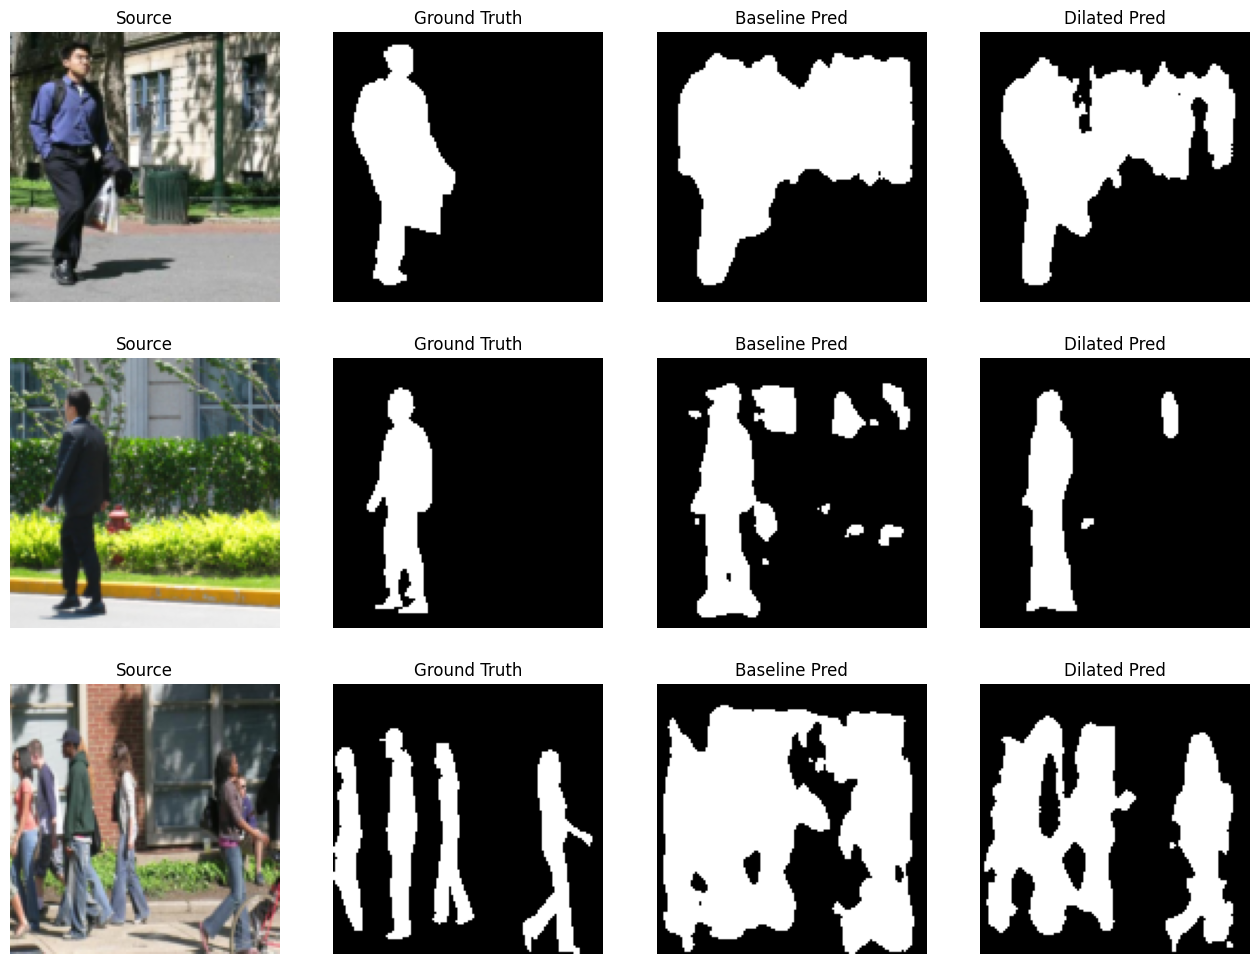

In [4]:
# 4. TRAINING & EVIDENCE GENERATION
import time
import torch.optim as optim
import matplotlib.pyplot as plt

def train_model(model, name, device, epochs=20):
    print(f"\n========== STARTING BUDGET: {name} ==========")
    print(f"Total Parameters: {count_params(model)}")
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    # Class weighting to balance pedestrian detection
    weights = torch.tensor([0.2, 0.8]).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)

    model.train()
    total_batches = len(train_loader)

    for epoch in range(epochs):
        loss_val = 0
        for b_idx, (imgs, masks) in enumerate(train_loader):
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), masks)
            loss.backward()
            optimizer.step()
            loss_val += loss.item()

            # Print batch progress nicely
            if (b_idx + 1) % 5 == 0 or (b_idx + 1) == total_batches:
                print(f"   [Epoch {epoch+1}/{epochs}] Batch {b_idx+1}/{total_batches} processed...")

        print(f"-> Epoch {epoch+1} Completed | Average Loss: {loss_val/total_batches:.4f}")

def evaluate_model(model, name, device):
    print(f"\n--- Evaluating {name} ---")
    model.eval()
    total_ious, valid_batches = np.zeros(2), np.zeros(2)

    start_time = time.time()
    with torch.no_grad():
        for b_idx, (imgs, masks) in enumerate(test_loader):
            imgs, masks = imgs.to(device), masks.to(device)
            preds = torch.argmax(model(imgs), dim=1)

            for cls in range(2):
                p_inds = (preds == cls)
                t_inds = (masks == cls)
                intersection = (p_inds[t_inds]).long().sum().item()
                union = p_inds.long().sum().item() + t_inds.long().sum().item() - intersection

                if union != 0:
                    total_ious[cls] += float(intersection) / float(max(union, 1))
                    valid_batches[cls] += 1
            print(f"   Evaluated test batch {b_idx+1}/{len(test_loader)}")

    latency = time.time() - start_time
    per_cls_iou = total_ious / np.maximum(valid_batches, 1)

    print(f"\n[EVIDENCE FOR {name}]")
    print(f"Latency: {latency:.2f} seconds")
    print(f"Background IoU: {per_cls_iou[0]:.4f} | Pedestrian IoU: {per_cls_iou[1]:.4f} | mIoU: {np.mean(per_cls_iou):.4f}")

def visualize(model_base, model_dilated, dataloader, device, num_samples=3):
    print(f"\n--- Generating Visual Evidence for {num_samples} Images ---")
    model_base.eval()
    model_dilated.eval()

    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))
    img_cnt = 0

    with torch.no_grad():
        for imgs, masks in dataloader:
            imgs, masks = imgs.to(device), masks.to(device)
            p_base = torch.argmax(model_base(imgs), dim=1)
            p_dil = torch.argmax(model_dilated(imgs), dim=1)

            for i in range(imgs.size(0)):
                if img_cnt >= num_samples: return

                print(f"   Plotting Image {img_cnt+1}/{num_samples}...")

                # Un-normalize
                img_v = imgs[i].cpu().permute(1, 2, 0).numpy()
                img_v = np.clip(np.array([0.229, 0.224, 0.225]) * img_v + np.array([0.485, 0.456, 0.406]), 0, 1)

                axes[img_cnt, 0].imshow(img_v); axes[img_cnt, 0].set_title("Source"); axes[img_cnt, 0].axis('off')
                axes[img_cnt, 1].imshow(masks[i].cpu().numpy(), cmap='gray'); axes[img_cnt, 1].set_title("Ground Truth"); axes[img_cnt, 1].axis('off')
                axes[img_cnt, 2].imshow(p_base[i].cpu().numpy(), cmap='gray'); axes[img_cnt, 2].set_title("Baseline Pred"); axes[img_cnt, 2].axis('off')
                axes[img_cnt, 3].imshow(p_dil[i].cpu().numpy(), cmap='gray'); axes[img_cnt, 3].set_title("Dilated Pred"); axes[img_cnt, 3].axis('off')

                img_cnt += 1
    plt.tight_layout()
    plt.show()

# --- EXECUTION SCRIPT ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nSystem active on: {device}")

m_base = UNet(use_dilation=False)
m_dil = UNet(use_dilation=True)

train_model(m_base, "BASELINE", device, epochs=20)
train_model(m_dil, "DILATED BOTTLENECK", device, epochs=20)

evaluate_model(m_base, "BASELINE", device)
evaluate_model(m_dil, "DILATED BOTTLENECK", device)

visualize(m_base, m_dil, test_loader, device, num_samples=3)